# 07 · Model 5: LightGBM (untuned baseline)
**Owner:** Sanchita · **Family:** Boosting · **Script:** `models/train_lgbm.py`

**Why this model for PathSnap?** Gradient-boosted trees are the strongest general-purpose learner on tabular features. Each tree corrects the previous trees' errors, interactions are learned automatically, and the output is a log-loss-trained probability, which fits the HMM.

**Strengths:** high accuracy on tabular data, fast leaf-wise training (about 6 s), fast inference, small model file (about 1 MB), built-in imbalance handling.

**Limitations:** more hyperparameters to set (learning rate, leaves, regularisation), and it can overfit with large trees, hence Bayesian tuning (notebook 09).

**Loss / objective:** binary log loss minimised by gradient boosting (400 trees, lr 0.05, 63 leaves, row/feature subsampling 0.8, class_weight='balanced').

**Protocol (same for all 5 models, `models/common.py`):** 5-fold **GroupKFold by trip** on the 78 clean training trips (trips 54 and 33 excluded) → refit on all of them → evaluate on the 10 student_test trips (every GPS point). Primary metric: **observation-level Top-1 accuracy**. Only one fixed configuration per model: **no grid or random search** (organiser rule). Only the selected model is tuned, with Bayesian optimisation.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from models.train_lgbm import est, cfg
from models.common import run_experiment
from pathsnap.features import FEATURE_COLUMNS
print("hyperparameters:", cfg)
est

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


hyperparameters: {'n_estimators': 400, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 20, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'class_weight': 'balanced'}


,boosting_type,'gbdt'
,num_leaves,63
,max_depth,-1
,learning_rate,0.05
,n_estimators,400
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## Train, cross-validate and evaluate

In [2]:
row, model = run_experiment("lightgbm", "Boosting", est, cfg)
pd.Series(row).drop("config_json")

[lightgbm] train rows=587,684 trips=78 | test rows=131,630


[lightgbm] CV macroF1=0.9114±0.0130 CV top1=0.8737 | test top1=0.8827 macroF1=0.9133 logloss=0.1149 cont=0.9547 | fit 6.5s, infer 43 ms/trip


model                        lightgbm
family                       Boosting
cv_macro_f1_mean             0.911352
cv_macro_f1_std              0.012978
cv_top1_mean                 0.873664
cv_top1_std                   0.02716
cv_logloss                   0.123984
train_top1                   0.917502
train_macro_f1               0.933879
test_top1                    0.882724
test_macro_f1                0.913331
test_precision               0.777859
test_recall                  0.948079
test_logloss                 0.114912
test_cand_miss_rate          0.002818
test_route_continuity_clf    0.954688
train_time_s                     6.45
infer_ms_per_trip                42.8
train_rows                     587684
seed                               42
dtype: object

In [3]:
log = json.load(open("results/model_runs/lightgbm.json"))
folds = pd.DataFrame(log["folds"]); display(folds.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
folds.plot(x="fold", y=["top1_accuracy", "macro_f1"], marker="o", ax=ax[0]); ax[0].set_title("Per-fold CV scores"); ax[0].set_ylim(0.75, 1)
bars = pd.Series({"train (fit data)": row["train_top1"], "CV (mean)": row["cv_top1_mean"], "student_test": row["test_top1"]})
bars.plot.bar(ax=ax[1], color=["C2", "C0", "C1"]); ax[1].set_ylim(0.75, 1); ax[1].set_title("Top-1: train vs CV vs test (over/underfitting)")
for i, v in enumerate(bars): ax[1].text(i, v + .005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

,macro_f1,precision,recall,logloss,top1_accuracy,candidate_miss_rate,fold,fit_s
0,0.8963,0.7654,0.9019,0.1485,0.8342,0.0074,0,13.32
1,0.9278,0.8205,0.9461,0.1030,0.8992,0.0176,1,8.98
2,0.9014,0.7545,0.9345,0.1263,0.8571,0.0165,2,5.11
3,0.9202,0.7944,0.9484,0.1024,0.8903,0.0028,3,5.18
4,0.9110,0.7815,0.9508,0.1397,0.8874,0.0009,4,5.29


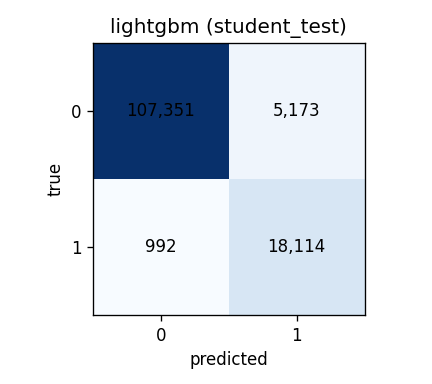

In [4]:
from IPython.display import Image
Image("results/plots/confusion_lightgbm.png")

## Feature importance (gain)

In [5]:
g = pd.Series(model.booster_.feature_importance("gain"), index=FEATURE_COLUMNS)
g = (100 * g / g.sum()).sort_values()
plt.figure(figsize=(7, 5)); g.plot.barh(); plt.title("LightGBM feature importance (% of total gain)")
plt.tight_layout(); plt.savefig("results/plots/lgbm_importance.png"); plt.show()
g.sort_values(ascending=False).head(8).round(1)

dist_minus_min         39.4
dist_rank              15.6
heading_cos_x_speed    14.8
heading_diff            8.9
mean_dist_window        4.2
arc_length_m            3.5
at_endpoint             3.3
speed_mps               2.4
dtype: float64

In [6]:
r = row
gap = r["train_top1"] - r["cv_top1_mean"]
verdict = "overfitting (large train-CV gap)" if gap > 0.05 else ("mild overfitting" if gap > 0.02 else "no overfitting (train ≈ CV; if anything, high bias)")
print(f"""Student-test results  : Top-1 {r['test_top1']:.4f} | macro F1 {r['test_macro_f1']:.4f} | precision {r['test_precision']:.4f} | recall {r['test_recall']:.4f} | log loss {r['test_logloss']:.4f}
Route continuity (classifier-only argmax): {r['test_route_continuity_clf']:.4f}
CV Top-1 {r['cv_top1_mean']:.4f} ± {r['cv_top1_std']:.4f} | CV macro F1 {r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}
Train Top-1 {r['train_top1']:.4f} -> train-CV gap {gap:+.4f}: {verdict}
Fit time {r['train_time_s']:.1f} s | inference {r['infer_ms_per_trip']:.0f} ms per trip""")

Student-test results  : Top-1 0.8827 | macro F1 0.9133 | precision 0.7779 | recall 0.9481 | log loss 0.1149
Route continuity (classifier-only argmax): 0.9547
CV Top-1 0.8737 ± 0.0272 | CV macro F1 0.9114 ± 0.0130
Train Top-1 0.9175 -> train-CV gap +0.0438: mild overfitting
Fit time 6.5 s | inference 43 ms per trip
